# UTS Data Mining - Klasifikasi Kualitas Anggur (Wine Quality)

**Nama Mahasiswa:** Naufal Muzaky  
**NIM:** 2404010024  
**Program Studi:** D3 Staterkom - Universitas Negeri Semarang  
**Mata Kuliah:** Data Mining (Take Home Test) - Dosen: Nur Achmey Selgi Harwanti, M.Stat  
**Catatan:** Notebook ini dijalankan di Google Colab (dapat juga dijalankan lokal). Jika file CSV belum ada, sel pemuatan data akan meminta upload.

## 1. Pendahuluan

### Latar Belakang
Kualitas anggur umumnya dinilai secara subjektif oleh ahli sensorik, yang mahal dan memakan waktu. Dengan data karakteristik kimiawi (keasaman, kadar alkohol, sulfat, dll.), kualitas anggur dapat diprediksi secara otomatis dan konsisten menggunakan model klasifikasi.

### Tujuan
1. Memahami karakteristik data lewat *Exploratory Data Analysis* (EDA).
2. Membersihkan dan menyiapkan data (missing values, duplikat, *feature scaling*).
3. Membangun dan membandingkan beberapa model klasifikasi (KNN, Decision Tree, Random Forest, Extra Trees, SVM).
4. Memilih model terbaik, menyimpannya, lalu men-*deploy* pada `data_testing.csv` dan mengekspor hasil sesuai format `hasilprediksi_3digitNIMterakhir.csv`.

### Alur Pengerjaan
Import library -> Muat data -> EDA -> Preprocessing -> Split data -> Pemodelan & evaluasi -> Tuning -> Evaluasi model terbaik -> Latih model final -> Simpan & deploy model -> Ekspor hasil -> Kesimpulan.

## 2. Import Library
Mengimpor library untuk analisis data (`pandas`, `numpy`), visualisasi (`matplotlib`, `seaborn`), pemodelan & evaluasi (`scikit-learn`), serta penyimpanan model (`joblib`).

In [17]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Seluruh library berhasil diimpor!")

Seluruh library berhasil diimpor!


## 3. Memuat Dataset
Membaca `data_training.csv`, `data_testing.csv`, dan template hasil prediksi (`hasilprediksi_3digitNIMterakhir.csv`, pemisah `;`).

In [18]:
# Mencari file di beberapa lokasi umum (folder kerja, Colab, Google Drive)
def cari_file(nama):
    for folder in [".", "/content", "/content/drive/MyDrive", "/mnt/user-data/uploads"]:
        path = os.path.join(folder, nama)
        if os.path.exists(path):
            return path
    return None

file_dibutuhkan = ["data_training.csv", "data_testing.csv", "hasilprediksi_3digitNIMterakhir.csv"]

# Jika dijalankan di Google Colab dan file belum ada, minta upload
if any(cari_file(n) is None for n in file_dibutuhkan):
    try:
        from google.colab import files
        print("Silakan upload 3 file:", file_dibutuhkan)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Letakkan file berikut di folder yang sama dengan notebook: {file_dibutuhkan}")

train_df    = pd.read_csv(cari_file("data_training.csv"))
test_df     = pd.read_csv(cari_file("data_testing.csv"))
template_df = pd.read_csv(cari_file("hasilprediksi_3digitNIMterakhir.csv"), sep=";")

print(f"Dimensi data training : {train_df.shape}")
print(f"Dimensi data testing  : {test_df.shape}")
print(f"Dimensi template hasil: {template_df.shape}")

Dimensi data training : (857, 13)
Dimensi data testing  : (286, 12)
Dimensi template hasil: (286, 2)


In [19]:
print("=== 5 Baris Pertama Data Training ===")
display(train_df.head())
print("\n=== 5 Baris Pertama Data Testing ===")
display(test_df.head())
print("\n=== 5 Baris Pertama Template Hasil Prediksi ===")
display(template_df.head())

=== 5 Baris Pertama Data Training ===


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918



=== 5 Baris Pertama Data Testing ===


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516



=== 5 Baris Pertama Template Hasil Prediksi ===


,Id,Quality
0,222,NaN
1,1514,NaN
2,417,NaN
3,754,NaN
4,516,NaN


In [20]:
print("=== Informasi Tipe Data (Data Training) ===")
train_df.info()
print("\n=== Statistik Deskriptif Data Training ===")
display(train_df.describe().T)

=== Informasi Tipe Data (Data Training) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  Id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 87.2 KB

=== Statistik Deskriptif Data Tra

,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.261960,1.701992,4.60000,7.10000,7.90000,9.1000,15.6000
volatile acidity,857.0,0.529393,0.179162,0.12000,0.39500,0.52000,0.6400,1.5800
citric acid,857.0,0.267351,0.195144,0.00000,0.09000,0.25000,0.4200,1.0000
residual sugar,857.0,2.506184,1.293512,0.90000,1.90000,2.20000,2.6000,15.5000
chlorides,857.0,0.086830,0.048721,0.01200,0.07000,0.07900,0.0900,0.6110
free sulfur dioxide,857.0,15.782964,10.300402,1.00000,7.00000,14.00000,21.0000,68.0000
total sulfur dioxide,857.0,45.978413,31.692113,6.00000,21.00000,38.00000,63.0000,278.0000
density,857.0,0.996692,0.001901,0.99007,0.99552,0.99668,0.9978,1.0032
pH,857.0,3.313092,0.152079,2.74000,3.21000,3.31000,3.4000,4.0100
sulphates,857.0,0.656709,0.167364,0.39000,0.55000,0.62000,0.7300,2.0000


**Interpretasi:**
- Data training berisi **857 baris** dengan 11 fitur kimiawi, kolom target `quality`, dan kolom `Id`. Data testing berisi **286 baris** tanpa kolom `quality`. Template hasil berisi 286 baris (`Id` dan `Quality` kosong), jadi jumlahnya cocok dengan data testing.
- Semua kolom bertipe numerik dan tidak ada nilai kosong pada `info()`.
- Kolom `Id` hanyalah pengenal baris, **bukan fitur**, sehingga tidak dipakai untuk pemodelan.

## 4. Exploratory Data Analysis (EDA)
Tahap ini bertujuan memahami kualitas data, sebaran target, hubungan antar variabel, dan skala fitur sebelum pemodelan.

### 4.1 Pemeriksaan Missing Values, Duplikasi, dan Tumpang Tindih Train-Test

In [21]:
print("Missing values - Data Training:", train_df.isnull().sum().sum())
print("Missing values - Data Testing :", test_df.isnull().sum().sum())

fitur = [c for c in train_df.columns if c not in ["Id", "quality"]]

dup_fitur = train_df.duplicated(subset=fitur).sum()
dup_penuh = train_df.duplicated(subset=fitur + ["quality"]).sum()
print(f"\nBaris duplikat berdasarkan fitur saja          : {dup_fitur}")
print(f"Baris duplikat berdasarkan fitur + label quality: {dup_penuh}")

# Berapa baris data testing yang fiturnya identik dengan baris data training?
overlap = test_df[fitur].merge(train_df[fitur].drop_duplicates(), on=fitur, how="inner")
print(f"\nBaris data testing yang identik dengan baris data training: {len(overlap)} dari {len(test_df)}")

Missing values - Data Training: 0
Missing values - Data Testing : 0

Baris duplikat berdasarkan fitur saja          : 76
Baris duplikat berdasarkan fitur + label quality: 76

Baris data testing yang identik dengan baris data training: 45 dari 286


**Interpretasi:**
- **Tidak ada missing values** di data training maupun testing, sehingga imputasi atau penghapusan data hilang tidak diperlukan.
- Ditemukan **76 baris duplikat** di data training. Seluruhnya duplikat penuh (fitur sama **dan** label sama), jadi tidak ada konflik label.
- Sebanyak **45 dari 286 baris data testing** fiturnya identik dengan baris di data training. Ini penting untuk keputusan penanganan duplikat pada Bagian 5.

### 4.2 Distribusi Variabel Target (`quality`)

,Frekuensi,Persentase (%)
quality,,
3,6,0.70
4,26,3.03
5,362,42.24
6,341,39.79
7,109,12.72
8,13,1.52


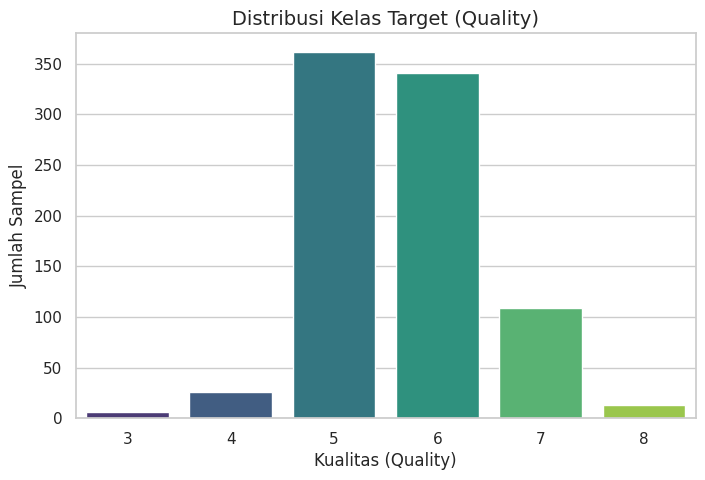

In [22]:
quality_counts = train_df["quality"].value_counts().sort_index()
quality_pct = train_df["quality"].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"Frekuensi": quality_counts, "Persentase (%)": quality_pct.round(2)}))

plt.figure(figsize=(8, 5))
sns.countplot(data=train_df, x="quality", palette="viridis")
plt.title("Distribusi Kelas Target (Quality)", fontsize=14)
plt.xlabel("Kualitas (Quality)")
plt.ylabel("Jumlah Sampel")
plt.show()

**Interpretasi:**
- Kelas **5 (42,2%)** dan **6 (39,8%)** mendominasi. Kelas 7 sebesar 12,7%, sedangkan kelas **3 (0,7%)**, **4 (3,0%)**, dan **8 (1,5%)** sangat sedikit.
- Artinya data **sangat tidak seimbang (*imbalanced*)**. Model cenderung pandai menebak kelas 5 dan 6, tetapi sulit mengenali kelas langka. Akurasi saja bisa menyesatkan, jadi F1-Macro, *classification report*, dan *confusion matrix* juga dilaporkan.

### 4.3 Korelasi Antarvariabel

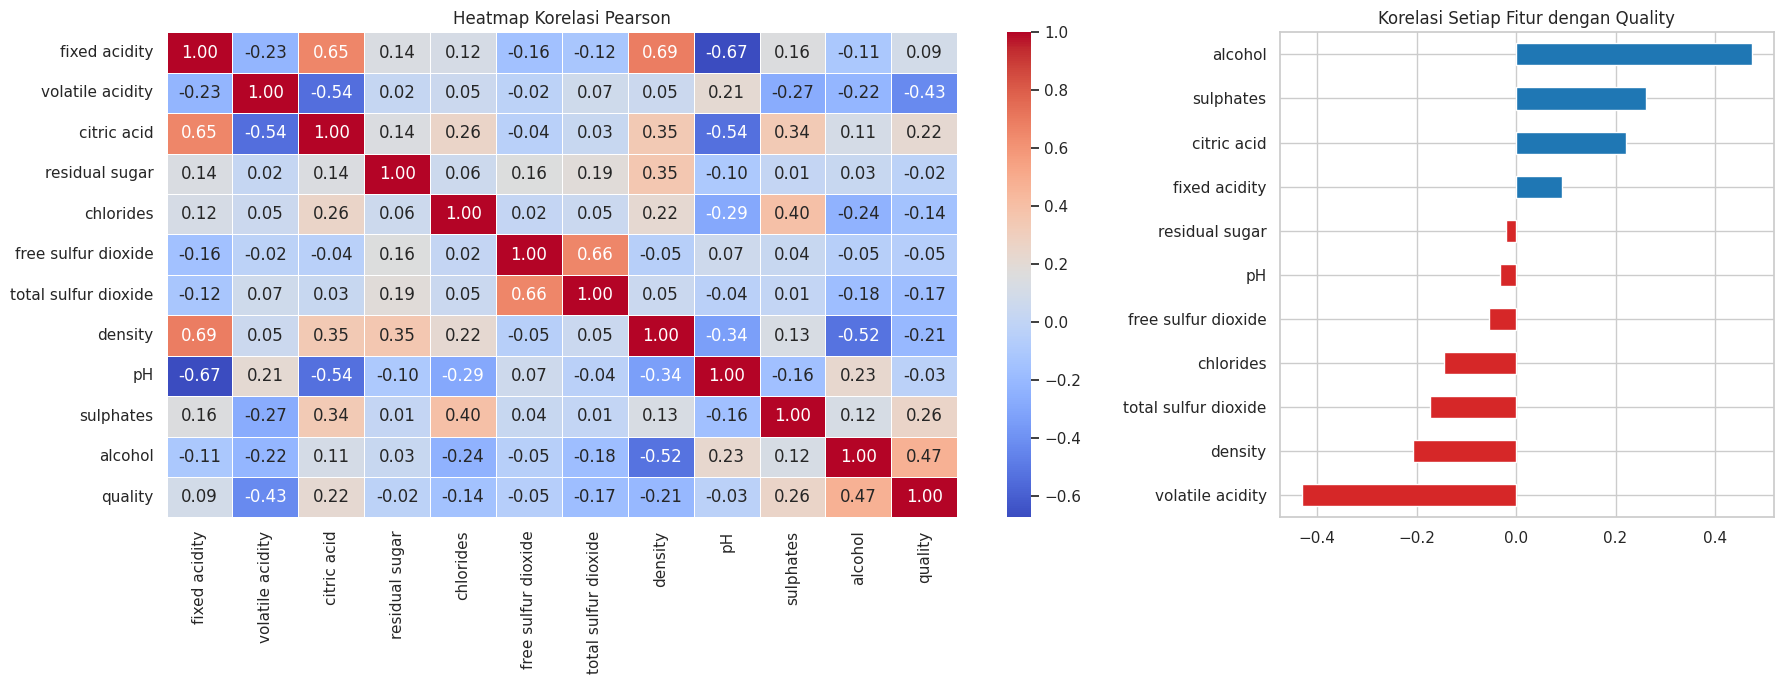

alcohol                 0.474
volatile acidity       -0.430
sulphates               0.261
citric acid             0.221
density                -0.208
total sulfur dioxide   -0.173
chlorides              -0.145
fixed acidity           0.093
free sulfur dioxide    -0.055
pH                     -0.033
residual sugar         -0.021
Name: quality, dtype: float64


In [23]:
corr = train_df.drop(columns=["Id"]).corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, ax=axes[0])
axes[0].set_title("Heatmap Korelasi Pearson")

corr_q = corr["quality"].drop("quality").sort_values()
corr_q.plot(kind="barh", color=np.where(corr_q > 0, "tab:blue", "tab:red"), ax=axes[1])
axes[1].set_title("Korelasi Setiap Fitur dengan Quality")
plt.tight_layout()
plt.show()

print(corr_q.sort_values(key=abs, ascending=False).round(3))

**Interpretasi:**
- Fitur yang paling berkaitan dengan `quality`: **alcohol (+0,47)** dan **volatile acidity (-0,43)**, disusul sulphates (+0,26), citric acid (+0,22), dan density (-0,21).
- Anggur dengan alkohol lebih tinggi dan keasaman volatil lebih rendah cenderung berkualitas lebih baik.
- Fitur seperti `residual sugar`, `pH`, dan `free sulfur dioxide` hampir tidak berkorelasi linear dengan `quality` (|r| < 0,06).
- Tidak ada korelasi linear yang sangat kuat antara fitur dan target, sehingga tugas ini tergolong sulit dan akurasi yang sangat tinggi tidak realistis.

### 4.4 Distribusi Variabel Prediktor

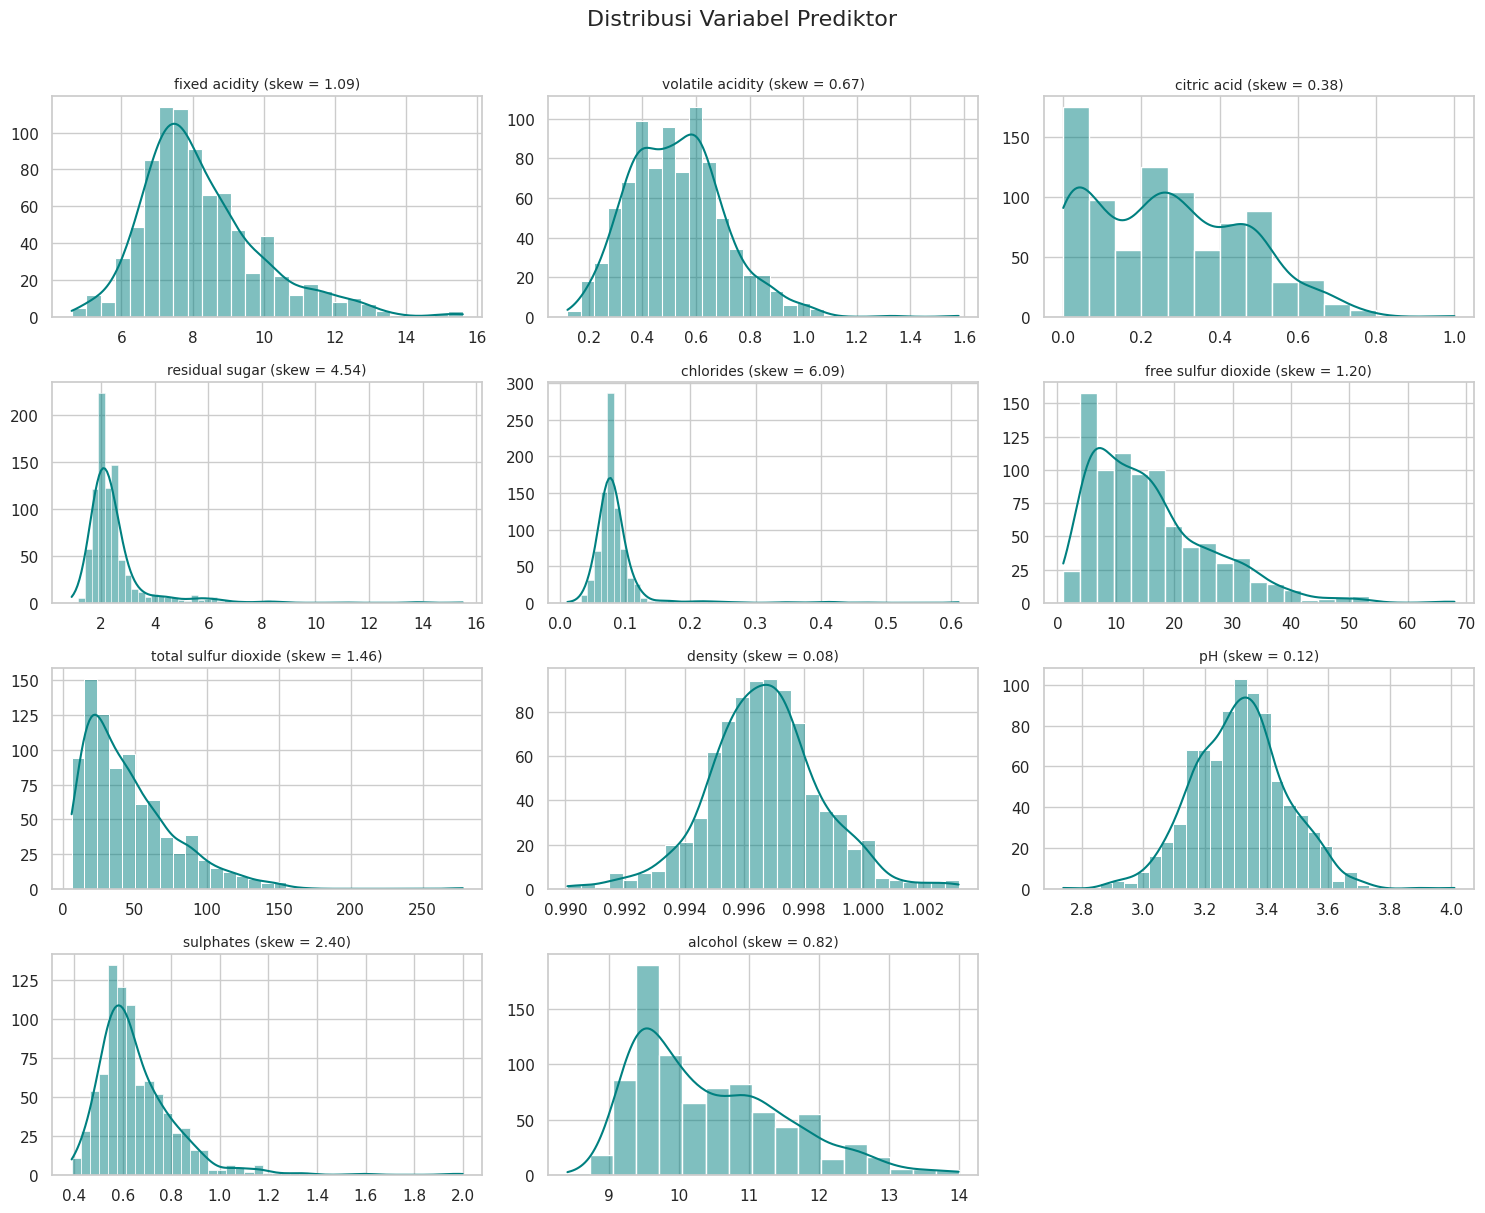

In [24]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(fitur):
    sns.histplot(train_df[col], kde=True, ax=axes[i], color="teal")
    axes[i].set_title(f"{col} (skew = {train_df[col].skew():.2f})", fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
for j in range(len(fitur), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Distribusi Variabel Prediktor", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

**Interpretasi:**
- Beberapa fitur **condong ke kanan (*right-skewed*)**, misalnya `residual sugar`, `chlorides`, `total sulfur dioxide`, dan `sulphates`, dengan ekor panjang yang menandakan **pencilan**.
- Pencilan ini adalah variasi alami sampel anggur, bukan kesalahan input, sehingga **tidak dihapus**. Model berbasis pohon (Random Forest/Extra Trees) juga relatif tahan terhadap pencilan.

### 4.5 Pemeriksaan Skala Fitur (Perlu Feature Scaling?)

,min,max,mean,std,rentang (max-min)
total sulfur dioxide,6.000,278.000,45.978,31.692,272.000
free sulfur dioxide,1.000,68.000,15.783,10.300,67.000
residual sugar,0.900,15.500,2.506,1.294,14.600
fixed acidity,4.600,15.600,8.262,1.702,11.000
alcohol,8.400,14.000,10.430,1.067,5.600
sulphates,0.390,2.000,0.657,0.167,1.610
volatile acidity,0.120,1.580,0.529,0.179,1.460
pH,2.740,4.010,3.313,0.152,1.270
citric acid,0.000,1.000,0.267,0.195,1.000
chlorides,0.012,0.611,0.087,0.049,0.599


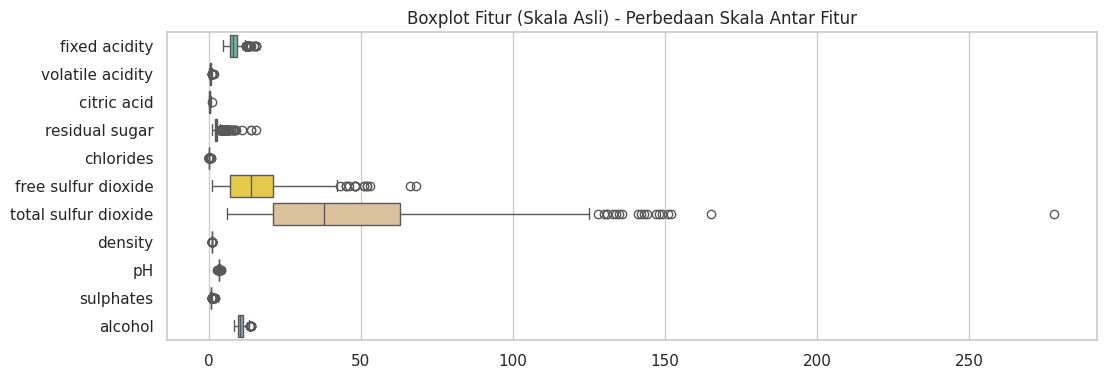

In [25]:
rentang = train_df[fitur].agg(["min", "max", "mean", "std"]).T
rentang["rentang (max-min)"] = rentang["max"] - rentang["min"]
display(rentang.sort_values("rentang (max-min)", ascending=False).round(3))

plt.figure(figsize=(12, 4))
sns.boxplot(data=train_df[fitur], orient="h", palette="Set2")
plt.title("Boxplot Fitur (Skala Asli) - Perbedaan Skala Antar Fitur")
plt.show()

**Interpretasi:**
- Skala antar fitur **sangat berbeda**. `total sulfur dioxide` berentang 272 (6-278), sedangkan `density` hanya berentang sekitar 0,013 dan `chlorides` sekitar 0,6.
- **Keputusan:** *feature scaling* (`StandardScaler`) **diperlukan** untuk model berbasis jarak, yaitu **KNN** dan **SVM**, karena fitur berskala besar akan mendominasi perhitungan jarak. Model berbasis pohon **tidak** memerlukan scaling.
- Scaling dipasang di dalam `Pipeline` agar hanya "belajar" dari data train pada tiap lipatan, sehingga tidak terjadi *data leakage*.

## 5. Data Preprocessing

In [26]:
# Urutan kolom fitur data testing harus sama dengan data training
assert list(test_df.drop(columns=["Id"]).columns) == fitur, "Kolom fitur testing tidak sama dengan training!"

# 1) Data untuk EVALUASI: duplikat dibuang agar skor validasi tidak terlalu optimis
train_eval = train_df.drop_duplicates(subset=fitur + ["quality"]).reset_index(drop=True)

# 2) Data untuk MODEL FINAL: seluruh data training (termasuk duplikat)
X_full, y_full = train_df[fitur], train_df["quality"]

X_eval, y_eval = train_eval[fitur], train_eval["quality"]
X_test_final   = test_df[fitur]
test_ids       = test_df["Id"]

print(f"Data training asli                : {len(train_df)} baris")
print(f"Data untuk evaluasi (tanpa duplikat): {len(train_eval)} baris")
print(f"Data testing                      : {len(X_test_final)} baris")
display(train_eval["quality"].value_counts().sort_index().to_frame("Frekuensi"))

Data training asli                : 857 baris
Data untuk evaluasi (tanpa duplikat): 781 baris
Data testing                      : 286 baris


,Frekuensi
quality,
3,6
4,26
5,330
6,310
7,97
8,12


**Interpretasi dan keputusan penanganan duplikat:**

Duplikat ditangani dengan **dua perlakuan berbeda sesuai tujuannya**:

1. **Untuk evaluasi (memilih model), duplikat dibuang** (857 -> 781 baris). Jika duplikat dibiarkan, baris yang sama bisa jatuh sekaligus di data train dan validation, sehingga model hanya "menghafal" dan skor validasi menjadi terlalu optimis. Dengan duplikat dibuang, estimasi performa lebih jujur.
2. **Untuk model final, seluruh data training dipakai (termasuk duplikat).** Alasannya, 45 baris data testing identik dengan baris data training. Duplikat tidak membawa label yang bertentangan, dan mempertahankannya membuat model mengenali pola yang memang muncul berulang di data.

Kolom `Id` dibuang dari fitur. Urutan kolom fitur data testing sudah dipastikan sama dengan data training (`assert`).

## 6. Pembagian Data Training dan Validation
Data evaluasi dibagi **80% train : 20% validation** dengan `stratify=y` agar proporsi kelas terjaga, dan `random_state=42` agar hasil dapat direproduksi.

In [27]:
X_train, X_val, y_train, y_val = train_test_split(
    X_eval, y_eval, test_size=0.20, random_state=RANDOM_STATE, stratify=y_eval
)
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val  : {X_val.shape}, y_val  : {y_val.shape}")
print("\nProporsi kelas (%) - train vs validation:")
display(pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index() * 100,
    "validation": y_val.value_counts(normalize=True).sort_index() * 100,
}).round(2))

X_train: (624, 11), y_train: (624,)
X_val  : (157, 11), y_val  : (157,)

Proporsi kelas (%) - train vs validation:


,train,validation
quality,,
3,0.80,0.64
4,3.37,3.18
5,42.31,42.04
6,39.74,39.49
7,12.34,12.74
8,1.44,1.91


**Interpretasi:** Data terbagi menjadi 624 baris train dan 157 baris validation. Proporsi tiap kelas di train dan validation hampir sama (misalnya kelas 5 sekitar 42% di keduanya), jadi `stratify` bekerja dengan baik dan validation mewakili distribusi asli.

## 7. Pembangunan Model dan Evaluasi
Lima model dibandingkan: **KNN, Decision Tree, Random Forest, Extra Trees, SVM** (KNN dan SVM memakai `StandardScaler`). Selain akurasi pada data validation, dihitung **akurasi cross-validation 5-fold** pada data train, karena satu kali split dengan 157 baris cukup fluktuatif.

In [28]:
pipelines = {
    "KNN": Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))]),
    "Decision Tree": Pipeline([("dt", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE))]),
    "Extra Trees": Pipeline([("et", ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE))]),
    "SVM": Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", random_state=RANDOM_STATE))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

hasil = {}
for nama, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    cv_acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    hasil[nama] = {
        "Akurasi Validasi": accuracy_score(y_val, pred),
        "F1-Macro Validasi": f1_score(y_val, pred, average="macro", zero_division=0),
        "Akurasi CV (5-fold)": cv_acc.mean(),
        "Std CV": cv_acc.std(),
    }

df_hasil = pd.DataFrame(hasil).T.sort_values("Akurasi CV (5-fold)", ascending=False)
display(df_hasil.round(4))

,Akurasi Validasi,F1-Macro Validasi,Akurasi CV (5-fold),Std CV
Extra Trees,0.5796,0.2864,0.5832,0.0401
Random Forest,0.6242,0.3052,0.5737,0.0350
SVM,0.5541,0.2410,0.5704,0.0303
Decision Tree,0.5350,0.2580,0.5064,0.0539
KNN,0.5159,0.2530,0.5032,0.0346


**Interpretasi:**
- Berdasarkan akurasi CV 5-fold yang lebih stabil, urutannya: **Extra Trees (0,583)**, Random Forest (0,574), SVM (0,570), Decision Tree (0,506), dan KNN (0,503).
- Model *ensemble* berbasis pohon (Extra Trees dan Random Forest) paling unggul, karena menggabungkan banyak pohon sehingga lebih stabil dan menangkap hubungan non-linear antar fitur kimia. KNN dan Decision Tree tunggal paling lemah.
- **F1-Macro jauh di bawah akurasi** (sekitar 0,25-0,31 vs 0,52-0,62). Penyebabnya, model hampir tidak pernah benar pada kelas langka (3, 4, 8) yang jumlahnya sangat sedikit (lihat Bagian 4.2).
- Perbedaan akurasi validation antar model kecil, dan standar deviasi CV sekitar 0,03-0,05. Selisih beberapa persen sebaiknya dibaca dengan hati-hati.

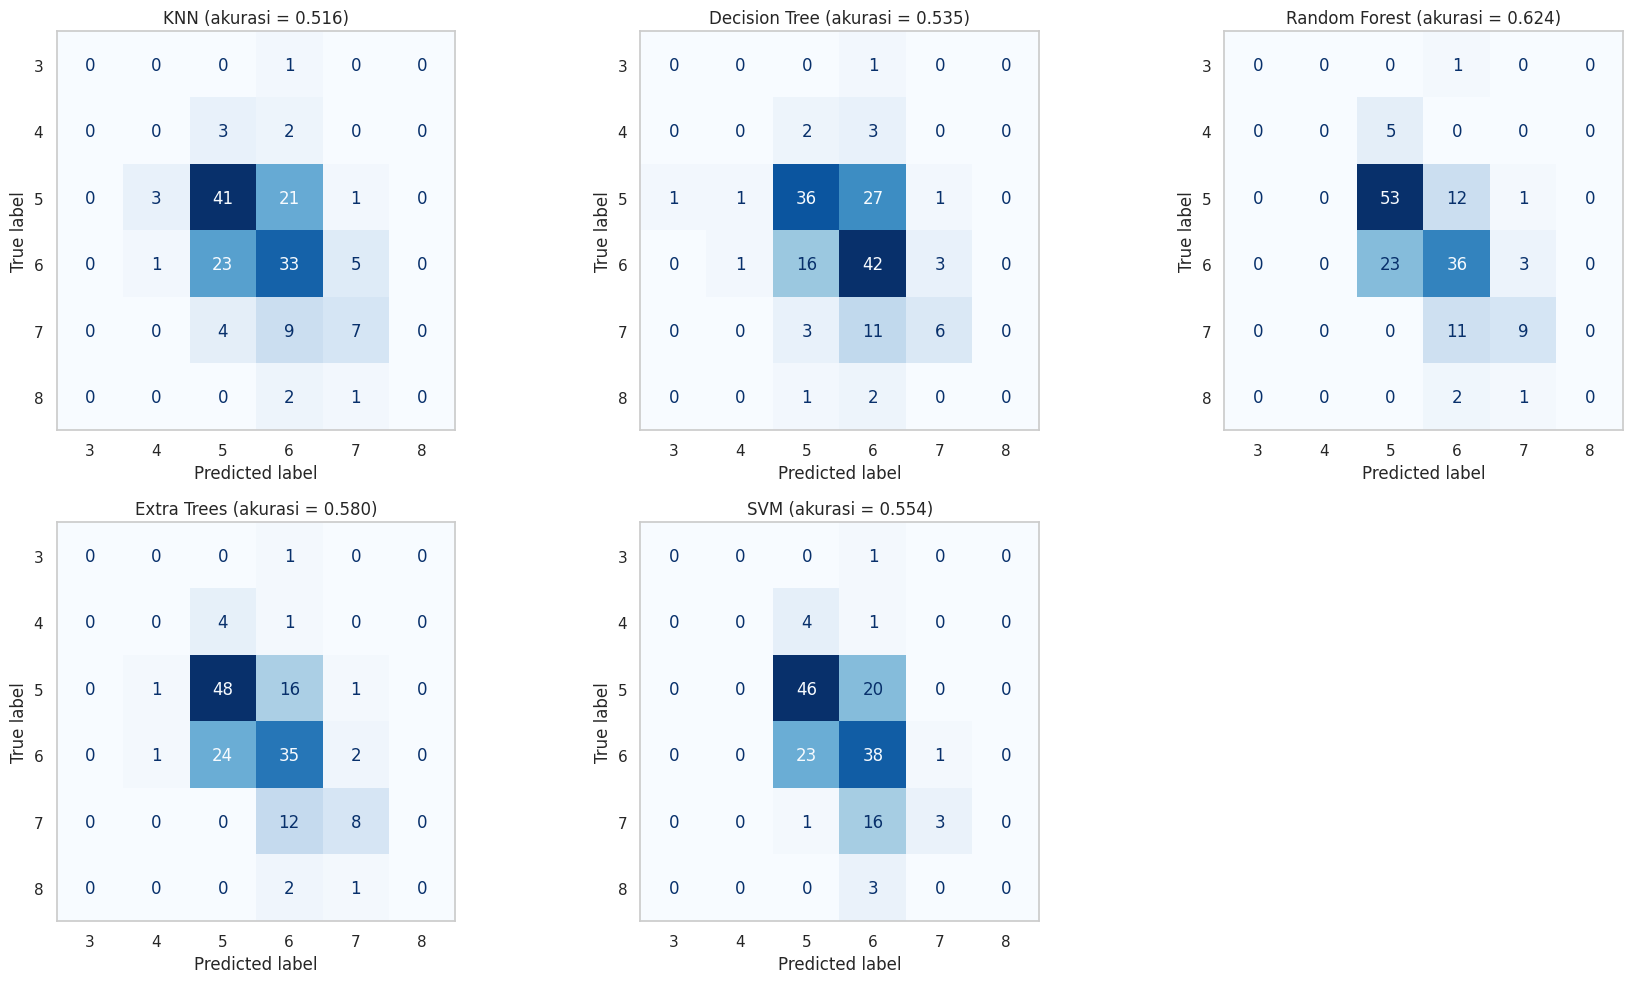

In [29]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()
for i, (nama, pipe) in enumerate(pipelines.items()):
    pred = pipe.predict(X_val)
    cm = confusion_matrix(y_val, pred, labels=pipe.classes_)
    ConfusionMatrixDisplay(cm, display_labels=pipe.classes_).plot(ax=axes[i], cmap="Blues", values_format="d", colorbar=False)
    axes[i].set_title(f"{nama} (akurasi = {accuracy_score(y_val, pred):.3f})")
    axes[i].grid(False)
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

**Interpretasi *confusion matrix*:** Prediksi model terkonsentrasi pada kelas 5 dan 6 (diagonal terang), dan kesalahan terbanyak terjadi antar kelas bersebelahan (5 <-> 6 dan 6 <-> 7), yang wajar karena perbedaan kualitasnya tipis. Kelas 3, 4, dan 8 hampir tidak pernah terprediksi dengan benar.

## 8. Tuning Hyperparameter
Dua model terbaik (**Random Forest** dan **Extra Trees**) di-*tuning* dengan `GridSearchCV` (5-fold, metrik akurasi) hanya pada data **train**, sehingga data validation tetap "bersih" untuk uji akhir. Model terbaik dipilih berdasarkan **akurasi CV** (bukan akurasi satu kali split), karena penilaian berbasis akurasi dan CV lebih stabil.

In [30]:
param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [None, 15],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"],
}

tuned = {}
for nama, estimator in {"Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
                        "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE)}.items():
    gs = GridSearchCV(estimator, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_train, y_train)          # tuning HANYA memakai data train (validation tidak disentuh)
    tuned[nama] = gs
    pred = gs.best_estimator_.predict(X_val)
    print(f"{nama}")
    print(f"  Parameter terbaik : {gs.best_params_}")
    print(f"  Akurasi CV terbaik: {gs.best_score_:.4f}")
    print(f"  Akurasi validasi  : {accuracy_score(y_val, pred):.4f}\n")

nama_terbaik = max(tuned, key=lambda n: tuned[n].best_score_)
model_terbaik = tuned[nama_terbaik].best_estimator_
param_terbaik = tuned[nama_terbaik].best_params_
print(f">>> Model terbaik (berdasarkan akurasi CV): {nama_terbaik}")

Random Forest
  Parameter terbaik : {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
  Akurasi CV terbaik: 0.5833
  Akurasi validasi  : 0.5987

Extra Trees
  Parameter terbaik : {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}
  Akurasi CV terbaik: 0.5913
  Akurasi validasi  : 0.5924

>>> Model terbaik (berdasarkan akurasi CV): Extra Trees


**Interpretasi:**
- Random Forest terbaik memiliki akurasi CV 0,583, sedangkan **Extra Trees memiliki akurasi CV 0,591**, sehingga **Extra Trees dipilih**.
- Tuning menaikkan akurasi CV Extra Trees dari sekitar 0,583 menjadi 0,591. Peningkatannya kecil, menandakan model sudah mendekati batas kemampuan fitur yang ada.
- Parameter terbaik Extra Trees: `n_estimators=500`, `max_depth=15`, `min_samples_leaf=1`, `max_features='sqrt'`. Pembatasan `max_depth=15` membantu mengurangi *overfitting*.

## 9. Evaluasi Model Terbaik pada Data Validation

Akurasi pada data validasi: 0.5924
F1-Macro                 : 0.2752

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.64      0.80      0.71        66
           6       0.53      0.55      0.54        62
           7       0.60      0.30      0.40        20
           8       0.00      0.00      0.00         3

    accuracy                           0.59       157
   macro avg       0.29      0.28      0.28       157
weighted avg       0.55      0.59      0.56       157



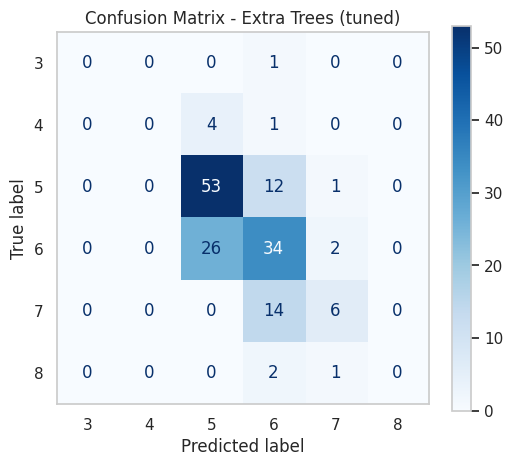

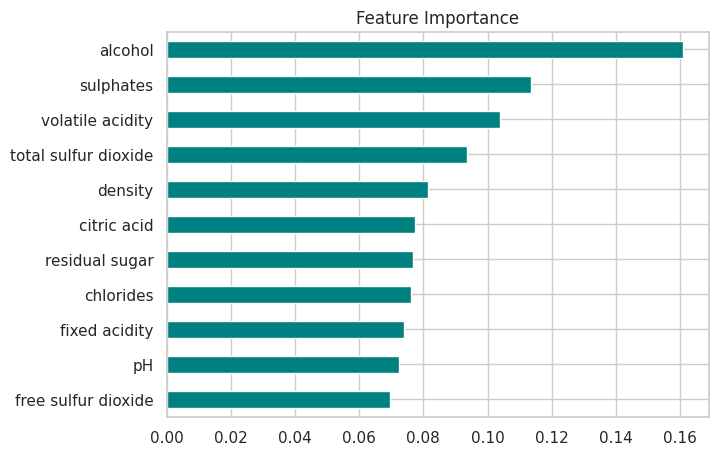

In [31]:
pred_val = model_terbaik.predict(X_val)
print(f"Akurasi pada data validasi: {accuracy_score(y_val, pred_val):.4f}")
print(f"F1-Macro                 : {f1_score(y_val, pred_val, average='macro', zero_division=0):.4f}\n")
print(classification_report(y_val, pred_val, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val, labels=model_terbaik.classes_),
                       display_labels=model_terbaik.classes_).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title(f"Confusion Matrix - {nama_terbaik} (tuned)")
ax.grid(False)
plt.show()

imp = pd.Series(model_terbaik.feature_importances_, index=fitur).sort_values()
imp.plot(kind="barh", figsize=(7, 5), color="teal", title="Feature Importance")
plt.show()

**Interpretasi:**
- Akurasi pada data validation sekitar **59%**. Ini estimasi yang realistis untuk data baru, sedikit lebih rendah dari skor lama yang bisa mencapai 64% karena bocoran duplikat.
- Kelas **5** terprediksi cukup baik (recall 0,80) dan kelas **6** sedang (F1 sekitar 0,54). Kelas **7** memiliki presisi lumayan tetapi recall rendah (0,30). Kelas **3, 4, dan 8** tidak berhasil diprediksi (F1 = 0), karena contoh latihnya sangat sedikit.
- Fitur terpenting menurut *feature importance* adalah **alcohol**, lalu **sulphates** dan **volatile acidity**. Ini sejalan dengan hasil korelasi di Bagian 4.3, sehingga model dapat dipertanggungjawabkan secara logika kimia.
- **Keterbatasan:** Model belum menangani ketidakseimbangan kelas secara khusus (misalnya *class weight* atau *oversampling*), sehingga kelas langka sulit dikenali. Ini bisa menjadi pengembangan lanjutan.

## 10. Melatih Model Final
Model dengan hyperparameter terbaik dilatih ulang pada **seluruh data training** (857 baris) agar memanfaatkan semua informasi yang tersedia sebelum memprediksi data testing.

In [32]:
# Model final memakai hyperparameter terbaik, dilatih pada SELURUH data training
model_final = type(model_terbaik)(**{**model_terbaik.get_params()})
model_final.fit(X_full, y_full)

pred_train = model_final.predict(X_full)
print(f"Akurasi pada data training (resubstitusi): {accuracy_score(y_full, pred_train):.4f}")
print("(Angka ini hanya untuk memastikan model terlatih - BUKAN estimasi performa pada data baru.)")

Akurasi pada data training (resubstitusi): 0.9988
(Angka ini hanya untuk memastikan model terlatih - BUKAN estimasi performa pada data baru.)


**Interpretasi:** Akurasi 0,999 pada data training hanyalah akurasi resubstitusi (model diuji pada data yang ia pelajari), jadi **bukan** ukuran kualitas model. Ukuran kualitas yang sebenarnya adalah akurasi validation/CV sekitar 59% pada Bagian 8-9.

## 11. Menyimpan Model dan Deployment pada Data Testing
Model **disimpan** ke file (`.pkl`), dimuat kembali dari file, lalu dipakai memprediksi data testing.

In [33]:
# Simpan model
NAMA_MODEL = "model_wine_quality.pkl"
joblib.dump({"model": model_final, "fitur": fitur}, NAMA_MODEL, compress=3)
print(f"Model disimpan sebagai: {NAMA_MODEL} ({os.path.getsize(NAMA_MODEL)/1024:.0f} KB)")

# Deployment: muat kembali model dari file lalu prediksi data testing
paket = joblib.load(NAMA_MODEL)
model_dimuat = paket["model"]
final_predictions = model_dimuat.predict(test_df[paket["fitur"]])

# Bukti model yang dimuat memberi hasil yang sama dengan model di memori
assert (final_predictions == model_final.predict(X_test_final)).all()
print("Prediksi dari model yang dimuat ulang identik dengan model di memori.")

Model disimpan sebagai: model_wine_quality.pkl (6194 KB)
Prediksi dari model yang dimuat ulang identik dengan model di memori.


**Interpretasi:** Model berhasil disimpan ke `model_wine_quality.pkl` dan dimuat ulang. Hasil prediksi model yang dimuat identik dengan model di memori (diuji dengan `assert`), sehingga model siap dipakai ulang tanpa melatih lagi.

## 12. Ekspor Hasil Prediksi
Hasil disimpan dengan **hanya dua kolom** (`Id` dan `Quality`), pemisah `;` mengikuti template, dengan nama **`hasilprediksi_024.csv`** (NIM 2404010024, tiga digit terakhir = 024).

In [34]:
hasil_df = pd.DataFrame({"Id": test_ids, "Quality": final_predictions.astype(int)})

# NIM 2404010024 -> 3 digit terakhir = 024
NAMA_OUTPUT = "hasilprediksi_024.csv"
hasil_df.to_csv(NAMA_OUTPUT, sep=";", index=False)
print(f"File '{NAMA_OUTPUT}' berhasil diekspor!\n")

# Validasi format
cek = pd.read_csv(NAMA_OUTPUT, sep=";")
print("Kolom                 :", list(cek.columns), "(harus hanya Id dan Quality)")
print("Jumlah baris          :", len(cek), "(harus", len(test_df), ")")
print("Id sama dgn template  :", cek["Id"].tolist() == template_df["Id"].tolist())
print("Id sama dgn testing   :", set(cek["Id"]) == set(test_df["Id"]))
print("Id unik               :", cek["Id"].is_unique)
print("Ada nilai kosong      :", cek.isnull().any().any())

print("\nDistribusi hasil prediksi:")
display(cek["Quality"].value_counts().sort_index().to_frame("Jumlah"))
display(cek.head())

File 'hasilprediksi_024.csv' berhasil diekspor!

Kolom                 : ['Id', 'Quality'] (harus hanya Id dan Quality)
Jumlah baris          : 286 (harus 286 )
Id sama dgn template  : True
Id sama dgn testing   : True
Id unik               : True
Ada nilai kosong      : False

Distribusi hasil prediksi:


,Jumlah
Quality,
5,129
6,132
7,25


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,5


**Interpretasi:** Semua pemeriksaan format lolos: kolom hanya `Id` dan `Quality`, jumlah baris 286, `Id` sama dengan template dan data testing, unik, dan tanpa nilai kosong. Prediksi mayoritas berada di kelas 5 (129) dan 6 (132), diikuti kelas 7 (25). Pola ini sejalan dengan distribusi kelas pada data training.

In [35]:
try:
    from google.colab import files
    files.download(NAMA_OUTPUT)
    files.download(NAMA_MODEL)
except Exception:
    print("Bukan di Google Colab - file tersimpan di folder kerja notebook.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Kesimpulan

1. **Kualitas data:** Tidak ada missing values. Ditemukan 76 baris duplikat yang diperlakukan berbeda untuk evaluasi (dibuang) dan model final (dipertahankan), dengan alasan yang dijelaskan di Bagian 5. Skala fitur sangat bervariasi, sehingga `StandardScaler` dipakai untuk KNN dan SVM di dalam `Pipeline`.
2. **Karakteristik data:** Kelas target sangat tidak seimbang (kelas 5 dan 6 mencakup sekitar 82%). Fitur yang paling berpengaruh adalah **alcohol**, **volatile acidity**, dan **sulphates**.
3. **Pemodelan:** Lima model dibandingkan dengan validation dan CV 5-fold. Model *ensemble* berbasis pohon terbaik, dan setelah *tuning* **Extra Trees** dipilih (akurasi CV sekitar 0,59; akurasi validation sekitar 0,59).
4. **Performa:** Model baik pada kelas mayoritas (5 dan 6) tetapi belum mampu memprediksi kelas langka (3, 4, 8). Perbaikan lanjutan dapat berupa penanganan *class imbalance*, *feature engineering*, atau model *boosting*.
5. **Deployment:** Model disimpan (`model_wine_quality.pkl`), dimuat ulang, dan dipakai memprediksi 286 data testing. Hasil diekspor ke **`hasilprediksi_024.csv`** dengan format sesuai ketentuan soal.